<a href="https://colab.research.google.com/github/Luuuuuig/Bachelor-End-Project/blob/main/Focal_Case_Selection_2026-10-07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Selecting the focal case
**7 October 2026 · Yijie's provisional assessment, before Zhongxin's**

This notebook applies the two-stage selection rule of the [methodology (§5.3)](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/Phase_1_Current_Methodology.md#53-formal-two-stage-selection-rule) to the six candidate areas from the [analysis notebook](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/Arno_Analysis_2026_10_02.ipynb): veto gates first (Stage A), then a weighted comparison of the candidates that remain (Stage B), then a sensitivity check.

## Summary

- **Provisional focal case: purchase-price control.** Support for checking supplier quotations and order confirmations against the PO: read the price and delivery date per line from the supplier's document, match the lines to the PO and flag differences for the buyer, who decides. Nothing changes in Exact without the buyer.
- **Stage A:** two of the six candidates leave the comparison. PO supplier communication fails gate 6 (ordinary automation is enough), and standard / review / manual fails gate 5 as a stand-alone candidate (it stays the design frame of the focal case). Maximalisatie and request intake continue in a narrower form; price control and article data pass provisionally.
- **Stage B:** price control scores **76.2 of 100**, 17.3 points ahead of request intake (58.9), article data (56.8) and maximalisatie (49.2). It scores highest or joint highest on every criterion.
- **Sensitivity:** price control stays ahead with equal weights, with every weight ±20%, with every single score ±1, with the price-only boundary, and in 99% of 10,000 random draws within the uncertainty ranges. It loses only when every uncertain score turns against it and for the others at the same time.
- **What could still change it:** its data-readiness and evaluation scores assume that the test account holds POs with their confirmations and a traceable approved price (checks PC1–PC4). Those checks come first.
- **Next:** Zhongxin sets her own weights without seeing these results, then reviews the gates, scores and focal case.

## Status and order of work

- **Provisional.** Several gates and scores rest on evidence that is expected but not yet seen, mainly in the Exact test account. Each such verdict names the check that settles it, using the IDs of the [Stage A worksheet](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Stage_A_Test_Account_Check_2026-10-07.xlsx). Each score has a low and a high value for that uncertainty.
- **Weights before scores.** The weights are Yijie's swing weights, [recorded](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Swing_Weights_Yijie_2026-10-07.md) and committed on 7 October before any candidate was scored.
- **Zhongxin's assessment follows.** She sets her own swing weights without seeing these results, then reviews the gates, the scores and the focal case. Her weights are then added to the sensitivity check.
- **Evidence.** Every verdict and score cites the [evidence matrix](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Candidate_Evidence_Matrix_2026-10-07.md); minutes are recorded minutes without former EXC, out of 560, from five sessions of one buyer.

## 1. Load the inputs

As in the course notebooks, the libraries are loaded once and the plot defaults set here. The weights, gate verdicts and scores are CSV files in `docs/analyze`, loaded from one version of the repository.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plots, as in the course notebooks
sns.set()                                  # set Seaborn defaults
plt.rcParams["figure.figsize"] = 10, 5     # default hor./vert. size of plots, in inches

In [2]:
# All inputs come from one version of the repository
commit = "9a0758de3cfca5eb3354cabd1a643e464f753af7"
repo = f"https://raw.githubusercontent.com/Luuuuuig/Bachelor-End-Project/{commit}/"

weights = pd.read_csv(repo + "docs/analyze/Swing_Weights_Yijie_2026-10-07.csv").set_index("criterion")
gates = pd.read_csv(repo + "docs/analyze/Stage_A_Gates_2026-10-07.csv", keep_default_na=False)
scores = pd.read_csv(repo + "docs/analyze/Candidate_Scores_2026-10-07.csv")

# Swing weights: each swing divided by the total
weights["weight"] = weights["swing"] / weights["swing"].sum()
weights.round(3)

,label,swing,weight
criterion,,,
workload,Observed workload contribution,100,0.270
business_value,Business value beyond counted workload,40,0.108
ai_fit,AI–task fit,50,0.135
data_readiness,Data readiness above the gate minimum,60,0.162
repetition,Repetition / process standardisation,30,0.081
prototype,Prototype / technical feasibility,40,0.108
evaluation,Evaluation feasibility,50,0.135


## 2. Stage A: veto gates

Each candidate is checked against six gates. A failed gate cannot be made up by a high score.

| Gate | Question |
|---|---|
| 1 | Are the required data and tools permitted for the research use? |
| 2 | Are the accessible data representative enough for a prototype and a test? |
| 3 | Can a reproducible reference answer and manual baseline be created? |
| 4 | Are critical errors detectable or reversible, with human review, an audit trail and a fallback? |
| 5 | Do the prototype and evaluation fit the BEP's time, access and participants? |
| 6 | Does AI support add value beyond a simpler rule? |

Verdicts: **Pass** (shown by the evidence), **Provisional pass** (expected, with the check that confirms it), **Redesign** (passes only in a narrower form, described in the reason) and **Reject**. A candidate with any Reject leaves the comparison; a candidate with a Redesign is scored in its narrowed form.

In [3]:
# Verdict per candidate and gate
gate_table = gates.pivot(index="candidate", columns="gate", values="verdict")
gate_table.columns = [f"Gate {g}" for g in gate_table.columns]
gate_table

,Gate 1,Gate 2,Gate 3,Gate 4,Gate 5,Gate 6
candidate,,,,,,
Article / supplier data,Provisional pass,Provisional pass,Provisional pass,Pass,Provisional pass,Provisional pass
Maximalisatie,Provisional pass,Redesign,Redesign,Pass,Provisional pass,Provisional pass
PO supplier communication,Provisional pass,Provisional pass,Pass,Provisional pass,Pass,Reject
Purchase-price control,Provisional pass,Provisional pass,Provisional pass,Provisional pass,Provisional pass,Provisional pass
Request intake & validation,Provisional pass,Redesign,Redesign,Pass,Provisional pass,Provisional pass
Standard / review / manual,Provisional pass,Provisional pass,Redesign,Redesign,Reject,Provisional pass


In [4]:
# Stage A result: the most severe verdict of each candidate
severity = {"Pass": 0, "Provisional pass": 1, "Redesign": 2, "Reject": 3}
labels = {0: "Pass", 1: "Provisional pass", 2: "Redesign", 3: "Reject"}
gates["severity"] = gates["verdict"].map(severity)
stage_a = gates.groupby("candidate")["severity"].max().map(labels).to_frame("stage_a_result")
stage_a["scored_in_stage_b"] = stage_a["stage_a_result"] != "Reject"
stage_a.sort_values("stage_a_result")

,stage_a_result,scored_in_stage_b
candidate,,
Article / supplier data,Provisional pass,True
Purchase-price control,Provisional pass,True
Maximalisatie,Redesign,True
Request intake & validation,Redesign,True
PO supplier communication,Reject,False
Standard / review / manual,Reject,False


In [5]:
# The reasons behind every Redesign and Reject
with pd.option_context("display.max_colwidth", 200):
    display(gates.loc[gates["verdict"].isin(["Redesign", "Reject"]), ["candidate", "gate", "verdict", "reason", "condition"]])

,candidate,gate,verdict,reason,condition
7,Maximalisatie,2,Redesign,"Full decision support needs past stock, advice and lead-time states, which a test copy is unlikely to hold. Narrowed: when a PO is created, show open POs and pending demand for the same supplier.","MX1, MX2"
8,Maximalisatie,3,Redesign,There is no reference for a good hold-or-order decision. The narrowed version can be checked against lines that were later added to open POs.,MX3
14,Standard / review / manual,3,Redesign,No reference standard exists without the buyer labelling past cases.,SR1
15,Standard / review / manual,4,Redesign,An automatic route conflicts with the buyers' concern of 1 October; acceptable only without autonomous processing.,"Arno session, part D"
16,Standard / review / manual,5,Reject,"As a stand-alone candidate, an end-to-end routing redesign with Exact integration does not fit the BEP. It stays the design frame for the chosen task: cases without a flag are standard, flagged ca...",
19,Request intake & validation,2,Redesign,"Requests arrive by email, at the desk or by phone and are probably not stored in Exact. Narrowed to what Exact holds: finding item history, old POs and drawings, and flagging missing information w...","RI1, RI2"
20,Request intake & validation,3,Redesign,There is no list of required drawings and no definition of a complete request. A reference exists only for retrieval: the drawing or old PO that was actually used.,RI3
29,PO supplier communication,6,Reject,Forwarding a generated PO with a standard message is a deterministic step; ordinary automation is enough. Kept as a quick-win recommendation.,


**Reading.**

- **Two candidates leave the comparison.** *PO supplier communication* fails gate 6: forwarding a generated PO with a standard message is a fixed step that ordinary automation can do, so it stays a quick-win recommendation. *Standard / review / manual* fails gate 5 as a stand-alone candidate: an end-to-end routing redesign with Exact integration does not fit the BEP. It stays the design frame for the chosen task, where cases without a flag follow the standard route and flagged cases go to the buyer for review.
- **Two candidates continue in a narrower form.** *Maximalisatie* has no reference for a good decision and no history of past stock and advice states, so it is scored as showing open POs and pending demand for the same supplier. *Request intake & validation* has no stored request history and no list of required drawings, so it is scored as finding history and drawings and flagging missing information at PO entry.
- **Two candidates pass provisionally.** *Purchase-price control* and *Article / supplier data* pass every gate on the evidence so far; each provisional verdict names the test-account check that confirms it.
- **Gate 1 is provisional for everyone**: Johan's permission covers the test-account data, but whether an external AI service may process its documents is still to be asked (checks G1–G2).

## 3. Stage B: weighted scores

Each remaining candidate gets a score from 1 to 5 per criterion, using the anchors of the [scoring brief](https://claude.ai/artifact/P2bsL8ZfyDhdJZanQAdk6n) (1 = weak or poorly supported, 3 = moderate with direct evidence, 5 = strong with direct evidence). The total is Σ(weight × score / 5), from 0 to 100.

Purchase-price control is scored with the boundary proposed in the brief (decision 5): checking orders and supplier confirmations against the PO and supplier information, with price as the main reported problem. Its workload is therefore the 98 minutes of order checks; the price-only boundary is a separate scenario in part 4.

In [6]:
# Scores of the candidates that passed Stage A
scored = scores.loc[scores["candidate"].isin(stage_a.index[stage_a["scored_in_stage_b"]])]
score_table = scored.pivot(index="candidate", columns="criterion", values="score")[weights.index]
score_table

criterion,workload,business_value,ai_fit,data_readiness,repetition,prototype,evaluation
candidate,,,,,,,
Article / supplier data,3,1,4,3,2,3,3
Maximalisatie,3,3,2,2,3,2,2
Purchase-price control,5,3,4,3,3,3,4
Request intake & validation,5,2,3,2,2,2,2


In [7]:
# Weighted totals: sum of weight x score / 5, as a number from 0 to 100
totals = (score_table @ weights["weight"] / 5 * 100).sort_values(ascending=False).to_frame("total")
totals["lead_over_next"] = totals["total"] - totals["total"].shift(-1)
totals.round(1)

,total,lead_over_next
candidate,,
Purchase-price control,76.2,17.3
Request intake & validation,58.9,2.2
Article / supplier data,56.8,7.6
Maximalisatie,49.2,NaN


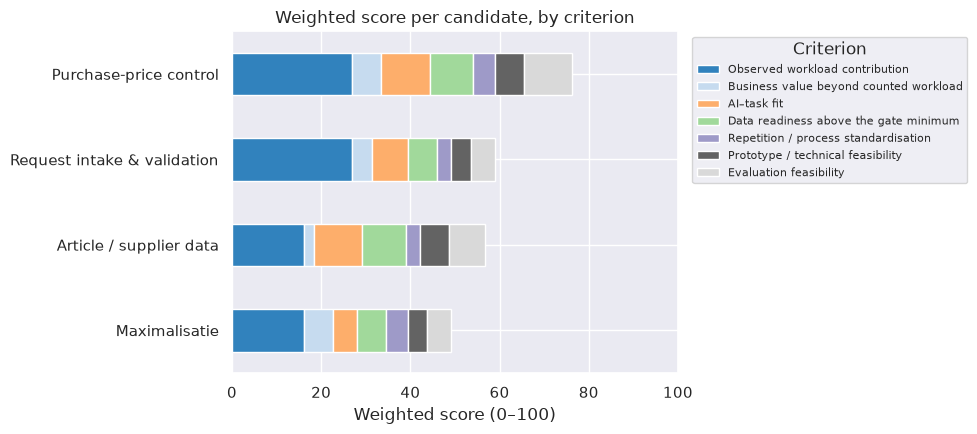

In [8]:
# Contribution of each criterion to each total
contributions = score_table.mul(weights["weight"], axis=1) / 5 * 100
contributions = contributions.loc[totals.index[::-1]]
contributions.columns = weights.loc[contributions.columns, "label"]

ax = contributions.plot(kind="barh", stacked=True, figsize=(10, 4.5), colormap="tab20c")
ax.set_xlabel("Weighted score (0–100)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Weighted score per candidate, by criterion")
ax.legend(title="Criterion", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
# The evidence behind each score
with pd.option_context("display.max_colwidth", 220, "display.max_rows", None):
    display(scored.sort_values(["candidate", "criterion"])[["candidate", "criterion", "score", "low", "high", "evidence"]])

,candidate,criterion,score,low,high,evidence
23,Article / supplier data,ai_fit,4,3,4,"Extracting item fields from supplier documents in different layouts is the core of the task; precedent Šimsa et al. (2023), a benchmark [AI table row 4]."
22,Article / supplier data,business_value,1,1,2,No effect named beyond buyer time.
24,Article / supplier data,data_readiness,3,2,4,"Article records exist; whether their source documents are linked is not yet known [checks AR1, AR2]."
27,Article / supplier data,evaluation,3,2,4,Existing article records can be the reference; few cases per week [check AR3].
26,Article / supplier data,prototype,3,2,4,"Can run on exported article records and supplier documents [checks G6, AR2]."
25,Article / supplier data,repetition,2,2,3,"Four of five days, 5 case-days; item data differ per article."
21,Article / supplier data,workload,3,3,3,"39 minutes (7.0%) on four days, 5 case-days; one case blocked for a day by missing data [notebook part 8]."
9,Maximalisatie,ai_fit,2,1,3,"The narrowed version is close to a rule (same supplier, open PO); AI only for matching demand descriptions [AI table row 8]."
8,Maximalisatie,business_value,3,2,3,"One effect named: each PO costs time and money (Dennis via Yijie, 2 October); example of 4 lines added to a 12-line PO (31 Aug OBS-15)."
10,Maximalisatie,data_readiness,2,1,3,Past advice and stock states are unlikely to be stored; open POs probably are [checks MX1–MX3].


**Reading.** Price control scores highest or joint highest on every criterion, so its lead does not depend on one weight. Its largest advantages over the runner-up, request intake, are evaluation feasibility (4 against 2: an approved price is a clear reference answer, while a complete request has no reference), data readiness (3 against 2) and AI–task fit (4 against 3). Request intake equals it on workload, as both take more than 15% of the recorded time, but scores lower on the criteria that decide whether a prototype can be built and tested. Article data has a good AI fit but a small workload (7%) and no business effect named. Maximalisatie in its narrowed form is close to a rule and has no reference for a good decision.

## 4. Sensitivity check

The methodology asks whether the leading candidate stays ahead when the assumptions change. Six checks:

1. **Equal weights** instead of the swing weights.
2. **Each weight ±20%**, one at a time, with the weights rescaled to 100%.
3. **Each score ±1**, one at a time (kept between 1 and 5).
4. **Price-only boundary** for purchase-price control: 28 minutes (5.0%) instead of 98, which gives a workload score of 3.
5. **Stress test**: every uncertain score at its low value for the leader and at its high value for all others, at the same time.
6. **All uncertainty at once**: 10,000 random draws, each score taken from its own low–high range.

In [10]:
# 1. Equal weights
equal = pd.Series(1 / len(weights), index=weights.index)
equal_totals = (score_table @ equal / 5 * 100).sort_values(ascending=False)
equal_totals.round(1)

candidate
Purchase-price control         71.4
Article / supplier data        54.3
Request intake & validation    51.4
Maximalisatie                  48.6
dtype: float64

In [11]:
# 2. Each weight 20% higher or lower, the others rescaled so the weights add up to 100%
rows = []
for criterion in weights.index:
    for change in [0.8, 1.2]:
        w = weights["weight"].copy()
        w[criterion] *= change
        w = w / w.sum()
        t = (score_table @ w / 5 * 100).sort_values(ascending=False)
        rows.append([criterion, f"{change - 1:+.0%}", t.index[0], t.iloc[0] - t.iloc[1]])
weight_checks = pd.DataFrame(rows, columns=["criterion", "weight_change", "leader", "lead_over_next"])
print("Leaders across the 14 weight changes:", weight_checks["leader"].value_counts().to_dict())
weight_checks.round(1)

Leaders across the 14 weight changes: {'Purchase-price control': 14}


,criterion,weight_change,leader,lead_over_next
0,workload,-20%,Purchase-price control,18.3
1,workload,+20%,Purchase-price control,16.4
2,business_value,-20%,Purchase-price control,17.2
3,business_value,+20%,Purchase-price control,17.4
4,ai_fit,-20%,Purchase-price control,17.2
5,ai_fit,+20%,Purchase-price control,17.4
6,data_readiness,-20%,Purchase-price control,17.2
7,data_readiness,+20%,Purchase-price control,17.4
8,repetition,-20%,Purchase-price control,17.3
9,repetition,+20%,Purchase-price control,17.3


In [12]:
# 3. Each score one point higher or lower, one at a time
rows = []
for candidate in score_table.index:
    for criterion in score_table.columns:
        for change in [-1, 1]:
            s = score_table.copy()
            s.loc[candidate, criterion] = min(5, max(1, s.loc[candidate, criterion] + change))
            t = (s @ weights["weight"] / 5 * 100).sort_values(ascending=False)
            rows.append([candidate, criterion, change, t.index[0], t.iloc[0] - t.iloc[1]])
score_checks = pd.DataFrame(rows, columns=["candidate", "criterion", "change", "leader", "lead_over_next"])
print("Leaders across the", len(score_checks), "score changes:", score_checks["leader"].value_counts().to_dict())
print("Smallest lead:", round(score_checks["lead_over_next"].min(), 1), "points")

Leaders across the 56 score changes: {'Purchase-price control': 56}
Smallest lead: 11.9 points


In [13]:
# 4. Price-only boundary for purchase-price control
price_only = score_table.copy()
price_only.loc["Purchase-price control", "workload"] = 3
price_only_totals = (price_only @ weights["weight"] / 5 * 100).sort_values(ascending=False)
price_only_totals.round(1)

candidate
Purchase-price control         65.4
Request intake & validation    58.9
Article / supplier data        56.8
Maximalisatie                  49.2
dtype: float64

In [14]:
# 5. Stress test: the leader at its low values, every other candidate at its high values
low = scored.pivot(index="candidate", columns="criterion", values="low")[weights.index]
high = scored.pivot(index="candidate", columns="criterion", values="high")[weights.index]
leader = totals.index[0]

stress = high.copy()
stress.loc[leader] = low.loc[leader]
stress_totals = (stress @ weights["weight"] / 5 * 100).sort_values(ascending=False)
stress_totals.round(1)

candidate
Request intake & validation    73.5
Article / supplier data        68.6
Purchase-price control         62.2
Maximalisatie                  57.3
dtype: float64

In [15]:
# 6. All uncertainty at once: each score drawn at random from its low-high range
rng = np.random.default_rng(20261007)
draws = 10000
wins = pd.Series(0, index=score_table.index)
for _ in range(draws):
    s = pd.DataFrame(rng.integers(low.to_numpy(), high.to_numpy() + 1), index=low.index, columns=low.columns)
    wins[(s @ weights["weight"]).idxmax()] += 1

(wins / draws * 100).sort_values(ascending=False).round(1).to_frame("share_of_draws_won_pct")

,share_of_draws_won_pct
candidate,
Purchase-price control,99.3
Request intake & validation,0.4
Article / supplier data,0.3
Maximalisatie,0.0


In [16]:
# Summary of the six checks
summary = pd.DataFrame([
    ["Swing weights (main result)", totals.index[0], totals["total"].iloc[0] - totals["total"].iloc[1]],
    ["1. Equal weights", equal_totals.index[0], equal_totals.iloc[0] - equal_totals.iloc[1]],
    ["2. Each weight ±20% (14 cases)", weight_checks["leader"].mode()[0] + f" in {(weight_checks['leader'] == leader).sum()} of 14", weight_checks["lead_over_next"].min()],
    ["3. Each score ±1 (" + str(len(score_checks)) + " cases)", score_checks["leader"].mode()[0] + f" in {(score_checks['leader'] == leader).sum()} of {len(score_checks)}", score_checks["lead_over_next"].min()],
    ["4. Price-only boundary", price_only_totals.index[0], price_only_totals.iloc[0] - price_only_totals.iloc[1]],
    ["5. Stress test", stress_totals.index[0], stress_totals.iloc[0] - stress_totals.iloc[1]],
    ["6. Random draws", wins.idxmax() + f" in {wins.max() / draws:.0%} of draws", np.nan],
], columns=["check", "leader", "smallest_lead_points"])
summary.round(1)

,check,leader,smallest_lead_points
0,Swing weights (main result),Purchase-price control,17.3
1,1. Equal weights,Purchase-price control,17.1
2,2. Each weight ±20% (14 cases),Purchase-price control in 14 of 14,16.4
3,3. Each score ±1 (56 cases),Purchase-price control in 56 of 56,11.9
4,4. Price-only boundary,Purchase-price control,6.5
5,5. Stress test,Request intake & validation,4.9
6,6. Random draws,Purchase-price control in 99% of draws,NaN


**Reading.** The four checks the methodology asks for (agreed weights, equal weights, each weight ±20%, each disputed score ±1) all keep price control in the lead, so by the methodology's rule the ranking is stable. The smallest lead is 11.9 points after a single score change and 16.4 after a weight change. With the price-only boundary, scored on the 28 minutes that name price, it still leads by 6.5 points.

The two extra checks show where the result could still turn. In 10,000 random draws within all uncertainty ranges, price control wins 99% of the time. It loses only in the stress test, where every uncertain score is at its worst for price control and at its best for every other candidate at once: request intake then leads with 73.5 against 62.2. That would need the test account to lack confirmations and approved prices, and request intake to turn out better than the evidence suggests on every uncertain criterion, keeping its full workload despite the narrower scope. The scores that decide this are price control's data readiness and evaluation feasibility, so checks PC1–PC4 in the test account come first.

## 5. The focal case

**Purchase-price control is the provisional focal case.**

**Task boundary** (brief, decision 5): checking supplier quotations before ordering and order confirmations after ordering against the PO and supplier information, with price as the main reported problem. Recorded workload: 98 of 560 minutes (17.5%) on all five days, of which 28 minutes are in records that name price explicitly.

**Proposed support, to be designed in Improve:** read the price, quantity and delivery date per line from the quotation or confirmation (scan, PDF, email or website), match the lines to the PO, and flag differences for the buyer. Within the standard / review / manual frame, lines without a difference follow the standard route and flagged lines go to the buyer for review. Nothing changes in Exact without the buyer, which stays within the buyers' concern of 1 October about autonomous order preparation.

**Conditions before Improve**, each a provisional Stage A verdict:

1. Johan confirms in writing that test-account data may be used, and whether an external AI service may process its documents (checks G1–G2). If not, the prototype uses tools that run locally.
2. The test account holds POs with their confirmations or quotations, and the approved price per line can be traced (checks PC1–PC4). If not, test cases are built from the examples of the five sessions and Zhongxin's test-workload fallback; data readiness then drops and part 4 is rerun.
3. Arno accepts that price and date differences are flagged for his review (session guide, part D, rows 5–6).
4. Zhongxin agrees with the gates, the scores and the focal case after setting her own weights; her weights are added to the sensitivity check.

**The other candidates:**

- **Request intake & validation** is the runner-up and the fallback if conditions 1–3 fail for price control.
- **PO supplier communication** becomes a quick-win recommendation with ordinary automation, outside the AI artifact.
- **Standard / review / manual** is the design frame of the focal case.
- **Article / supplier data** and **maximalisatie** are recorded as further opportunities.

**Limitations.** One assessor so far; Zhongxin's review follows. The evidence comes from five partial sessions of one buyer, and the kinds of work have not yet been checked by a second coder. The workload figures were known before the weights were set; the weights were recorded before any scoring. The verdicts and scores were drafted from the evidence matrix with AI assistance and reviewed by Yijie.